# Lab05_ML_SoilSensor
CSET480 IoT Analytics, Lab 5. Harshit Poonia, S24CSEU2835

## Part A - Setting Up

In [1]:
import warnings; warnings.filterwarnings("ignore")
import sklearn, pandas
print(sklearn.__version__, pandas.__version__)

1.7.2 2.3.3


## Part B - Creating the Dataset

In [2]:
import numpy as np, pandas as pd

rng = np.random.default_rng(42)
n = 24 * 90                              # 90 days, one reading per hour
t = pd.date_range("2026-09-01", periods=n, freq="h")
hour = t.hour.values
air = 26 + 8*np.sin((hour - 9)/24*2*np.pi) + rng.normal(0, 1.5, n)
hum = np.clip(60 - 1.6*(air - 26) + rng.normal(0, 6, n), 20, 95)
rain = np.where(rng.random(n) < 0.03, rng.uniform(1, 8, n), 0.0)

m = np.zeros(n); m[0] = 30; irr = np.zeros(n, dtype=int)
for i in range(n - 1):
    if hour[i] in (6, 18):               # waters at 06:00 and 18:00
        irr[i] = int(rng.random() < (0.85 if m[i] < 24 else 0.05))
    evap = 0.30 + 0.05*max(air[i] - 20, 0) * (1 - hum[i]/130)
    m[i+1] = np.clip(m[i] - evap + 1.2*rain[i] + 10*irr[i]
                     + rng.normal(0, 0.25), 8, 48)

soil_t = 22 + 0.5*(air - 26) + rng.normal(0, 0.4, n)
batt = 3.9 - 0.0008*np.arange(n)/24 + rng.normal(0, 0.01, n)

df = pd.DataFrame({"timestamp": t, "hour": hour,
    "air_temp_c": air.round(2), "humidity_pct": hum.round(1),
    "rain_mm": rain.round(1), "irrigated": irr,
    "soil_temp_c": soil_t.round(2), "soil_moisture_pct": m.round(2),
    "battery_v": batt.round(3)})

# the two things we want to predict (one hour ahead)
df["moisture_next_hr"] = df["soil_moisture_pct"].shift(-1)
df = df.iloc[:-1].copy()
df["low_next_hr"] = (df["moisture_next_hr"] < 20).astype(int)

# simulate sensor dropouts (missing readings)
for col, k in (("humidity_pct", 25), ("soil_moisture_pct", 10)):
    df.loc[df.sample(k, random_state=7).index, col] = np.nan

df.to_csv("soil_ml_data.csv", index=False)
print(df.shape)

(2159, 11)


## First seven days of data

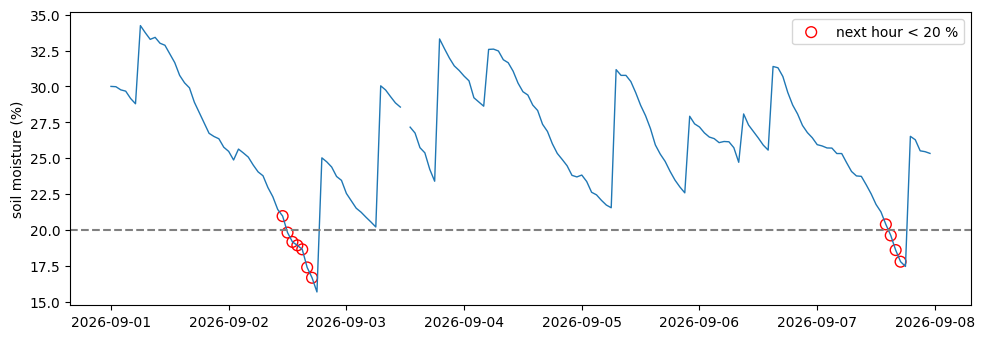

In [3]:
import matplotlib.pyplot as plt
w = df.iloc[:24*7]
plt.figure(figsize=(10,3.5))
plt.plot(w["timestamp"], w["soil_moisture_pct"], lw=1)
d1 = w[w["low_next_hr"]==1]
plt.scatter(d1["timestamp"], d1["soil_moisture_pct"], facecolors="none", edgecolors="red", s=60, label="next hour < 20 %")
plt.axhline(20, ls="--", c="grey")
plt.ylabel("soil moisture (%)"); plt.legend(); plt.tight_layout()
plt.savefig("screenshots/fig_7days.png", dpi=150)
plt.show()

## Part C - Step 1: size, missing values, class balance

In [4]:
import pandas as pd
df = pd.read_csv("soil_ml_data.csv", parse_dates=["timestamp"])

print(df.shape)                               # rows, columns
print(df.isna().sum()[lambda s: s > 0])       # columns with missing values
print(df["low_next_hr"].value_counts())       # class balance

(2159, 11)
humidity_pct         25
soil_moisture_pct    10
dtype: int64
low_next_hr
0    2042
1     117
Name: count, dtype: int64


## Part C - Step 2: which features relate to the answer

In [5]:
feats = ["hour", "air_temp_c", "humidity_pct", "rain_mm", "irrigated",
         "soil_temp_c", "soil_moisture_pct", "battery_v"]

corr = df[feats + ["low_next_hr"]].corr()["low_next_hr"]
print(corr.round(2).sort_values())

soil_moisture_pct   -0.45
irrigated           -0.05
rain_mm             -0.04
humidity_pct        -0.04
battery_v           -0.02
hour                 0.00
air_temp_c           0.06
soil_temp_c          0.06
low_next_hr          1.00
Name: low_next_hr, dtype: float64


## Part D - Preparing the Data

In [6]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

X, y = df[feats], df["low_next_hr"]

cut = int(len(df) * 0.8)       # first 80 % = past, last 20 % = future
Xtr, Xte = X.iloc[:cut], X.iloc[cut:]
ytr, yte = y.iloc[:cut], y.iloc[cut:]
print("train rows:", len(Xtr), "| test rows:", len(Xte))
print("dry events in test:", yte.sum())

def make_pipe(model):                         # fill gaps -> scale -> model
    return Pipeline([("fill", SimpleImputer(strategy="median")),
                     ("scale", StandardScaler()),
                     ("model", model)])

train rows: 1727 | test rows: 432
dry events in test: 26


## Part E - Decision Tree

In [7]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, classification_report

tree = make_pipe(DecisionTreeClassifier(max_depth=4, random_state=42))
tree.fit(Xtr, ytr)
pred = tree.predict(Xte)

print(confusion_matrix(yte, pred))
print(classification_report(yte, pred, target_names=["No (0)", "Yes (1)"]))
print("Always-say-No accuracy:", round((yte == 0).mean(), 3))

[[403   3]
 [  4  22]]
              precision    recall  f1-score   support

      No (0)       0.99      0.99      0.99       406
     Yes (1)       0.88      0.85      0.86        26

    accuracy                           0.98       432
   macro avg       0.94      0.92      0.93       432
weighted avg       0.98      0.98      0.98       432

Always-say-No accuracy: 0.94


## Part F - Comparing Four Classifiers

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score)

models = {
    "Logistic Regression":       LogisticRegression(max_iter=1000),
    "k-NN (k=5)":                KNeighborsClassifier(n_neighbors=5),
    "Decision Tree (depth 4)":   DecisionTreeClassifier(max_depth=4,
                                                        random_state=42),
    "Random Forest (100 trees)": RandomForestClassifier(n_estimators=100,
                                                        random_state=42),
}

fitted = {}
for name, model in models.items():
    fitted[name] = make_pipe(model).fit(Xtr, ytr)
    p = fitted[name].predict(Xte)
    print(f"{name:26s} acc {accuracy_score(yte, p):.2f}"
          f"  prec {precision_score(yte, p):.2f}"
          f"  rec {recall_score(yte, p):.2f}  f1 {f1_score(yte, p):.2f}")

Logistic Regression        acc 0.99  prec 0.96  rec 0.88  f1 0.92


k-NN (k=5)                 acc 0.96  prec 0.81  rec 0.50  f1 0.62
Decision Tree (depth 4)    acc 0.98  prec 0.88  rec 0.85  f1 0.86


Random Forest (100 trees)  acc 0.99  prec 0.92  rec 0.92  f1 0.92


## Part G - Which Sensors Matter

In [9]:
rf = fitted["Random Forest (100 trees)"]
imp = pd.Series(rf.named_steps["model"].feature_importances_, index=feats)
print(imp.sort_values(ascending=False).round(3))

soil_moisture_pct    0.683
air_temp_c           0.068
soil_temp_c          0.057
hour                 0.052
humidity_pct         0.049
irrigated            0.046
battery_v            0.044
rain_mm              0.001
dtype: float64


## Part H - Regression

In [10]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

yr = df["moisture_next_hr"]
ytr_r, yte_r = yr.iloc[:cut], yr.iloc[cut:]

naive = Xte["soil_moisture_pct"].fillna(Xtr["soil_moisture_pct"].median())
mae = mean_absolute_error(yte_r, naive)
print("Naive (next hour = now)   MAE", round(mae, 2))

rf_reg = RandomForestRegressor(n_estimators=100, random_state=42)
reg_models = {"Linear Regression": LinearRegression(),
              "Random Forest Regressor": rf_reg}
for name, model in reg_models.items():
    p = make_pipe(model).fit(Xtr, ytr_r).predict(Xte)
    mae, r2 = mean_absolute_error(yte_r, p), r2_score(yte_r, p)
    print(f"{name:24s}  MAE {mae:.2f}   R2 {r2:.3f}")

Naive (next hour = now)   MAE 0.92


Linear Regression         MAE 0.21   R2 0.997


Random Forest Regressor   MAE 0.28   R2 0.990


## Part I - Threshold Decision

In [11]:
lr = fitted["Logistic Regression"]
prob = lr.predict_proba(Xte)[:, 1]          # P(dry next hour)

print("threshold  alarms  caught(of 26)  precision  recall")
for th in (0.5, 0.3, 0.2, 0.1):
    flag = (prob >= th).astype(int)
    caught = int(((flag == 1) & (yte == 1)).sum())
    prec, rec = precision_score(yte, flag), recall_score(yte, flag)
    print(f"{th:>9}  {flag.sum():>6}  {caught:>13}  "
          f"{prec:>9.2f}  {rec:>6.2f}")

threshold  alarms  caught(of 26)  precision  recall
      0.5      24             23       0.96    0.88
      0.3      33             26       0.79    1.00
      0.2      37             26       0.70    1.00
      0.1      43             26       0.60    1.00


## Task 1: Fair test versus shuffled test

In [12]:
from sklearn.base import clone
from sklearn.model_selection import train_test_split
Xtr_s, Xte_s, ytr_s, yte_s = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
rows = []
for name, model in models.items():
    p_time = fitted[name].predict(Xte)
    p_shuf = make_pipe(clone(model)).fit(Xtr_s, ytr_s).predict(Xte_s)
    rows.append([name, f1_score(yte, p_time), recall_score(yte, p_time), f1_score(yte_s, p_shuf), recall_score(yte_s, p_shuf), accuracy_score(yte_s, p_shuf)])
t1 = pd.DataFrame(rows, columns=["model","time_F1","time_recall","shuf_F1","shuf_recall","shuf_acc"]).round(2)
print(t1.to_string(index=False))


                    model  time_F1  time_recall  shuf_F1  shuf_recall  shuf_acc
      Logistic Regression     0.92         0.88     0.82         0.70      0.98
               k-NN (k=5)     0.62         0.50     0.84         0.78      0.98
  Decision Tree (depth 4)     0.86         0.85     0.91         0.87      0.99
Random Forest (100 trees)     0.92         0.92     0.95         0.91      1.00


## Task 2: Lag features

In [13]:
from sklearn.base import clone
d2 = df.copy()
d2["moist_prev_hr"] = d2["soil_moisture_pct"].shift(1)
d2["moist_change"] = d2["soil_moisture_pct"] - d2["moist_prev_hr"]
d2 = d2.iloc[1:].copy()                       # first row has no previous hour
feats2 = feats + ["moist_prev_hr", "moist_change"]
X2, y2 = d2[feats2], d2["low_next_hr"]
cut2 = int(len(d2) * 0.8)
rows = []
for name in ["Logistic Regression", "Random Forest (100 trees)"]:
    pb = fitted[name].predict(Xte)
    pa = make_pipe(clone(models[name])).fit(X2.iloc[:cut2], y2.iloc[:cut2]).predict(X2.iloc[cut2:])
    ya = y2.iloc[cut2:]
    rows.append([name, precision_score(yte,pb), recall_score(yte,pb), f1_score(yte,pb), precision_score(ya,pa), recall_score(ya,pa), f1_score(ya,pa)])
t2 = pd.DataFrame(rows, columns=["model","prec_before","rec_before","f1_before","prec_lag","rec_lag","f1_lag"]).round(2)
print(t2.to_string(index=False))


                    model  prec_before  rec_before  f1_before  prec_lag  rec_lag  f1_lag
      Logistic Regression         0.96        0.88       0.92      0.92     0.88    0.90
Random Forest (100 trees)         0.92        0.92       0.92      0.92     0.92    0.92


## Task 3: Class imbalance

In [14]:
bal = {"Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
       "Decision Tree (depth 4)": DecisionTreeClassifier(max_depth=4, random_state=42, class_weight="balanced"),
       "Random Forest (100 trees)": RandomForestClassifier(n_estimators=100, random_state=42, class_weight="balanced")}
rows = []
for name, model in bal.items():
    pb = fitted[name].predict(Xte)
    pa = make_pipe(model).fit(Xtr, ytr).predict(Xte)
    rows.append([name, precision_score(yte,pb), recall_score(yte,pb), f1_score(yte,pb), precision_score(yte,pa), recall_score(yte,pa), f1_score(yte,pa)])
t3 = pd.DataFrame(rows, columns=["model","prec_before","rec_before","f1_before","prec_bal","rec_bal","f1_bal"]).round(2)
print(t3.to_string(index=False))


                    model  prec_before  rec_before  f1_before  prec_bal  rec_bal  f1_bal
      Logistic Regression         0.96        0.88       0.92      0.63     1.00    0.78
  Decision Tree (depth 4)         0.88        0.85       0.86      0.90     1.00    0.95
Random Forest (100 trees)         0.92        0.92       0.92      0.95     0.81    0.88


## Task 4: Choose your own threshold (Random Forest)

In [15]:
prob_rf = fitted["Random Forest (100 trees)"].predict_proba(Xte)[:, 1]

# highest threshold that still catches at least 95 % of the dry events
best = next(th for th in np.round(np.arange(0.99, 0, -0.01), 2)
            if recall_score(yte, (prob_rf >= th).astype(int)) >= 0.95)

print("threshold  alarms  caught(of %d)  false_alarms  precision  recall" % yte.sum())
for th in sorted({0.5, 0.4, 0.3, 0.2, 0.1, best}, reverse=True):
    flag = (prob_rf >= th).astype(int)
    caught = int(((flag == 1) & (yte == 1)).sum())
    print(f"{th:>9}  {flag.sum():>6}  {caught:>13}  {flag.sum()-caught:>12}  {precision_score(yte, flag, zero_division=0):>9.2f}  {recall_score(yte, flag):>6.2f}")
print("Highest threshold with recall >= 0.95:", best)

threshold  alarms  caught(of 26)  false_alarms  precision  recall
      0.5      26             24             2       0.92    0.92
      0.4      26             24             2       0.92    0.92
      0.3      28             24             4       0.86    0.92
     0.23      30             25             5       0.83    0.96
      0.2      31             26             5       0.84    1.00
      0.1      36             26            10       0.72    1.00
Highest threshold with recall >= 0.95: 0.23


## Task 5 (Extension): Feature selection

In [16]:
from sklearn.feature_selection import SelectKBest, f_classif
feats_nb = [f for f in feats if f != "battery_v"]
p_all = fitted["Random Forest (100 trees)"].predict(Xte)
p_nb = make_pipe(RandomForestClassifier(n_estimators=100, random_state=42)).fit(Xtr[feats_nb], ytr).predict(Xte[feats_nb])
print("(a) RF with battery_v    P %.2f R %.2f F1 %.2f" % (precision_score(yte,p_all), recall_score(yte,p_all), f1_score(yte,p_all)))
print("(a) RF without battery_v P %.2f R %.2f F1 %.2f" % (precision_score(yte,p_nb), recall_score(yte,p_nb), f1_score(yte,p_nb)))
print("\n(b) Logistic Regression with SelectKBest")
for k in (8, 5, 3):
    pipe = Pipeline([("fill", SimpleImputer(strategy="median")), ("scale", StandardScaler()),
                     ("select", SelectKBest(f_classif, k=k)), ("model", LogisticRegression(max_iter=1000))]).fit(Xtr, ytr)
    p = pipe.predict(Xte)
    kept = [f for f, s in zip(feats, pipe.named_steps["select"].get_support()) if s]
    print(f"k={k}: P {precision_score(yte,p):.2f} R {recall_score(yte,p):.2f} F1 {f1_score(yte,p):.2f} | kept: {kept}")


(a) RF with battery_v    P 0.92 R 0.92 F1 0.92
(a) RF without battery_v P 0.96 R 0.92 F1 0.94

(b) Logistic Regression with SelectKBest
k=8: P 0.96 R 0.88 F1 0.92 | kept: ['hour', 'air_temp_c', 'humidity_pct', 'rain_mm', 'irrigated', 'soil_temp_c', 'soil_moisture_pct', 'battery_v']


k=5: P 0.92 R 0.92 F1 0.92 | kept: ['air_temp_c', 'humidity_pct', 'irrigated', 'soil_temp_c', 'soil_moisture_pct']
k=3: P 0.84 R 0.62 F1 0.71 | kept: ['air_temp_c', 'soil_temp_c', 'soil_moisture_pct']


## Task 6 (Extension): Unsupervised learning (KMeans)

In [17]:
from sklearn.cluster import KMeans
km_X = SimpleImputer(strategy="median").fit_transform(df[["soil_moisture_pct", "air_temp_c"]])
km_Xs = StandardScaler().fit_transform(km_X)
df_k = df.copy()
df_k["cluster"] = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(km_Xs)
summary = df_k.groupby("cluster").agg(size=("cluster", "size"), avg_moisture=("soil_moisture_pct", "mean"),
                                      avg_air_temp=("air_temp_c", "mean"), share_label1=("low_next_hr", "mean")).round(3)
print(summary)


         size  avg_moisture  avg_air_temp  share_label1
cluster                                                
0         666        32.580        26.729         0.000
1         711        24.882        31.599         0.100
2         782        24.863        20.093         0.059


## Task 7 (Extension): Regression extension

In [18]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingRegressor
naive = Xte["soil_moisture_pct"].fillna(Xtr["soil_moisture_pct"].median())
print(f"{'Naive (next = now)':26s} MAE {mean_absolute_error(yte_r, naive):.2f}   R2 {r2_score(yte_r, naive):.3f}")
for name, model in {"Linear Regression": LinearRegression(), "Ridge (alpha=1)": Ridge(alpha=1.0),
                    "Gradient Boosting": GradientBoostingRegressor(random_state=42)}.items():
    p = make_pipe(model).fit(Xtr, ytr_r).predict(Xte)
    print(f"{name:26s} MAE {mean_absolute_error(yte_r, p):.2f}   R2 {r2_score(yte_r, p):.3f}")


Naive (next = now)         MAE 0.92   R2 0.818
Linear Regression          MAE 0.21   R2 0.997
Ridge (alpha=1)            MAE 0.21   R2 0.997


Gradient Boosting          MAE 0.28   R2 0.992
